In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [44]:
def make_barplot(cross):
    axes = cross.plot(kind="bar", stacked=True)

    for i, group in enumerate(cross.index):
        total = cross.loc[group].sum()
        stroke_count = cross.loc[group, "Yes"]
        percentage_across_group = stroke_count / total * 100
        axes.text(x=i, y=total, s=f"{percentage_across_group:.1f}%", ha="center", va="bottom", fontsize=10)

In [62]:
data = pd.read_csv("healthcare-dataset-stroke-data.csv")
print(data)

         Id  Gender   Age  Hypertension  Heart_disease Ever_married  \
0      9046    Male  67.0             0              1          Yes   
1     51676  Female  61.0             0              0          Yes   
2     31112    Male  80.0             0              1          Yes   
3     60182  Female  49.0             0              0          Yes   
4      1665  Female  79.0             1              0          Yes   
...     ...     ...   ...           ...            ...          ...   
5105  18234  Female  80.0             1              0          Yes   
5106  44873  Female  81.0             0              0          Yes   
5107  19723  Female  35.0             0              0          Yes   
5108  37544    Male  51.0             0              0          Yes   
5109  44679  Female  44.0             0              0          Yes   

          Work_type Residence_type  Avg_glucose_level   Bmi   Smoking_status  \
0           Private          Urban             228.69  36.6  former

Work_type_children               -0.083869
Smoking_status_Unknown           -0.055892
Work_type_Never_worked           -0.014882
Gender_Female                    -0.009027
Smoking_status_never smoked      -0.004129
Gender_Other                     -0.003166
Work_type_Govt_job                0.002677
Smoking_status_smokes             0.008939
Gender_Male                       0.009117
Work_type_Private                 0.011888
Residence_type                    0.015458
Bmi                               0.042374
Work_type_Self-employed           0.062168
Smoking_status_formerly smoked    0.064556
Ever_married                      0.108340
Hypertension                      0.127904
Avg_glucose_level                 0.131945
Heart_disease                     0.134914
Age                               0.245257
Stroke                            1.000000
Name: Stroke, dtype: float64


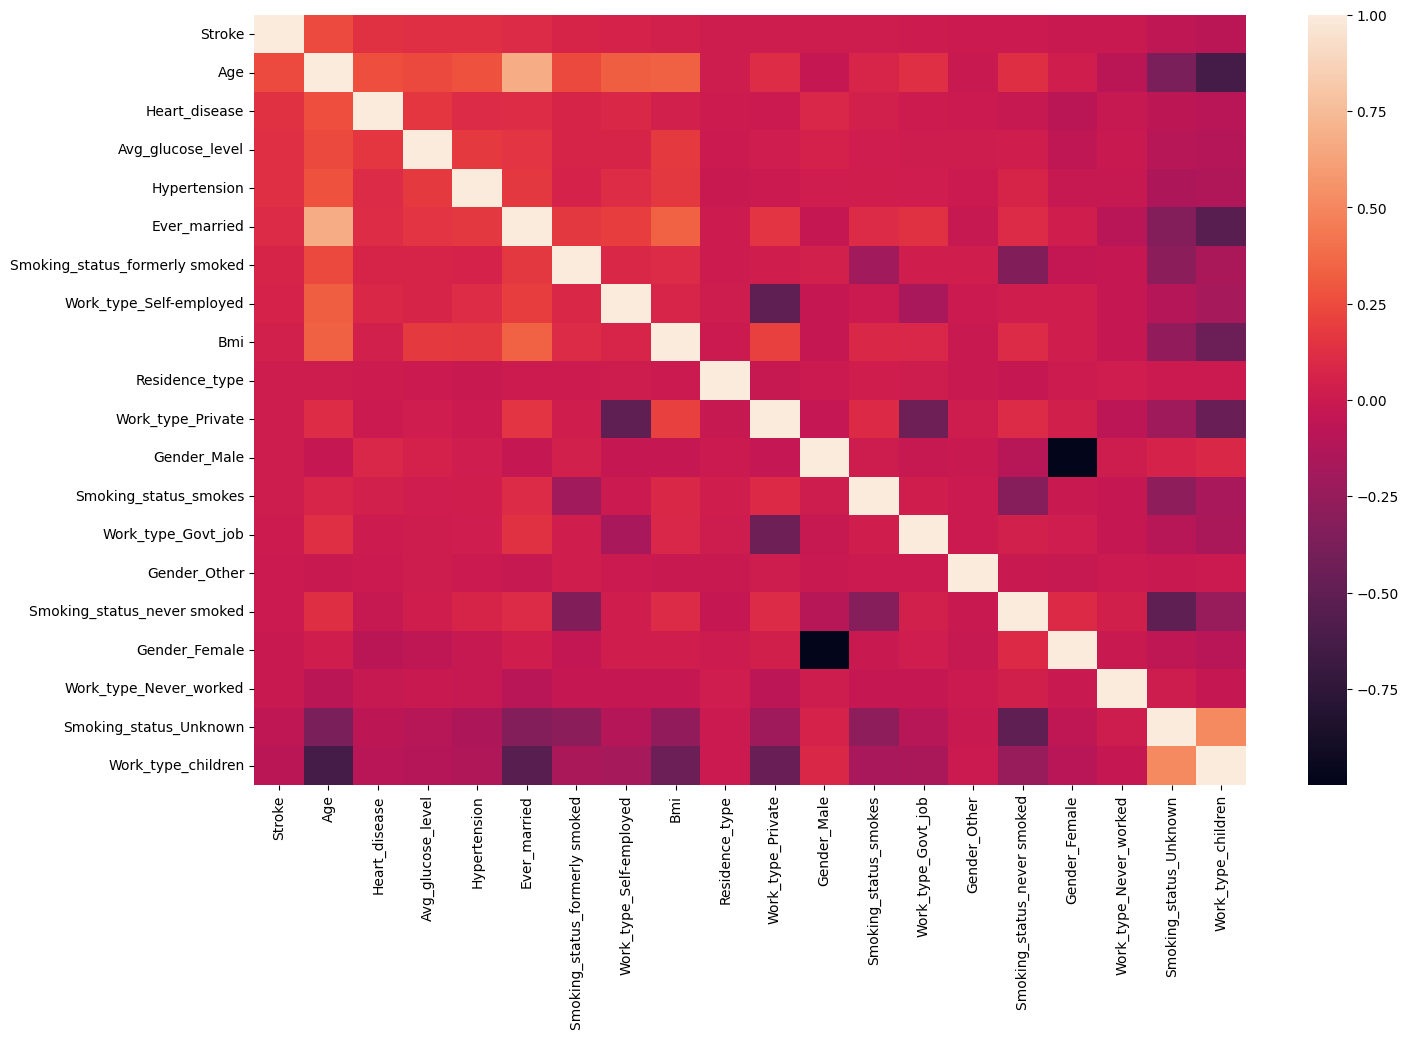

In [63]:
data["Ever_married"] = data["Ever_married"].map({"Yes": 1, "No": 0})
data["Residence_type"] = data["Residence_type"].map({"Urban": 1, "Rural": 0})
categorical_columns = data.select_dtypes(include="object").columns.to_list()
columns_numerical = data.columns[data.dtypes != "object"].to_list()
columns_numerical.remove("Id")

data_heatmap = pd.get_dummies(data[categorical_columns])

data_heatmap = pd.concat([data[columns_numerical], data_heatmap], axis=1)

corr = data_heatmap.corr()
print(corr["Stroke"].sort_values())
sorted_features = corr["Stroke"].sort_values(ascending=False).index
corr_sorted = corr.loc[sorted_features, sorted_features]

plt.figure(figsize=(16, 10))
sns.heatmap(corr_sorted)
plt.show()

In [47]:
data["Hypertension"] = data["Hypertension"].replace({0: "No", 1: "Yes"})
data["Heart_disease"] = data["Heart_disease"].replace({0: "No", 1: "Yes"})
data["Work_type"] = data["Work_type"].replace({"Govt_job": "Government job", "Never_worked": "Never worked", "children":"Children"})
data["Smoking_status"] = data["Smoking_status"].replace({"smokes": "Smokes", "never smoked": "Never smoked", "formerly smoked": "Formerly smoked"})
data["Stroke"] = data["Stroke"].replace({0: "No", 1: "Yes"})

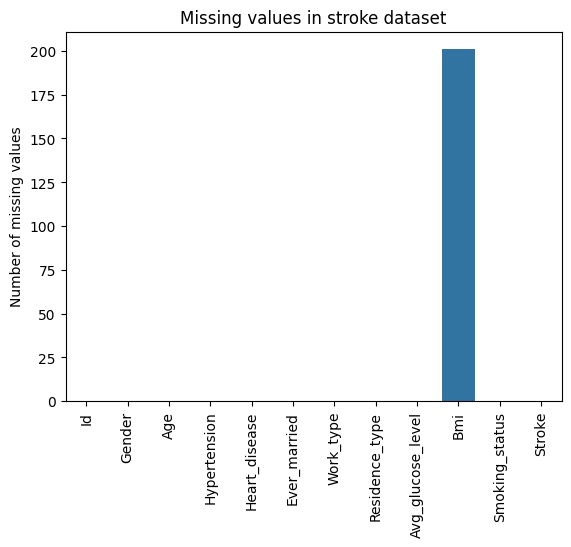

In [48]:
sns.barplot(data.isna().sum())
plt.xticks(rotation=90)
plt.title("Missing values in stroke dataset")
plt.ylabel("Number of missing values")
plt.show()

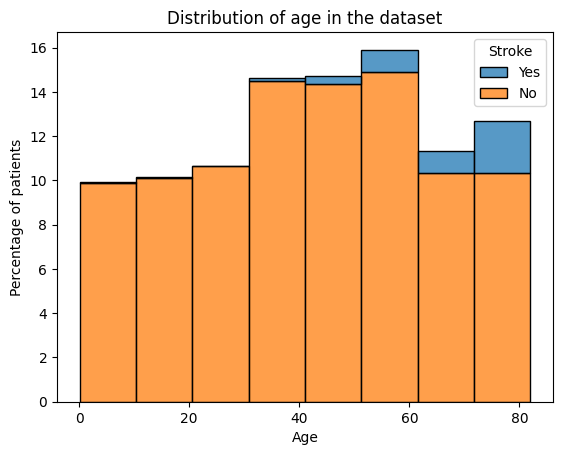

In [49]:
sns.histplot(data=data, x="Age", bins=8, hue="Stroke", multiple="stack", stat="percent")
plt.title("Distribution of age in the dataset")
plt.ylabel("Percentage of patients")
plt.show()

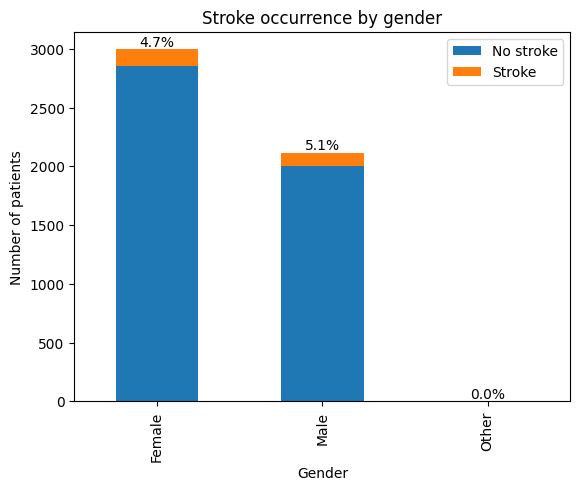

In [50]:
cross = pd.crosstab(data["Gender"], data["Stroke"])

make_barplot(cross)

plt.title("Stroke occurrence by gender")
plt.xlabel("Gender")
plt.ylabel("Number of patients")
plt.legend(["No stroke", "Stroke"])
plt.show()

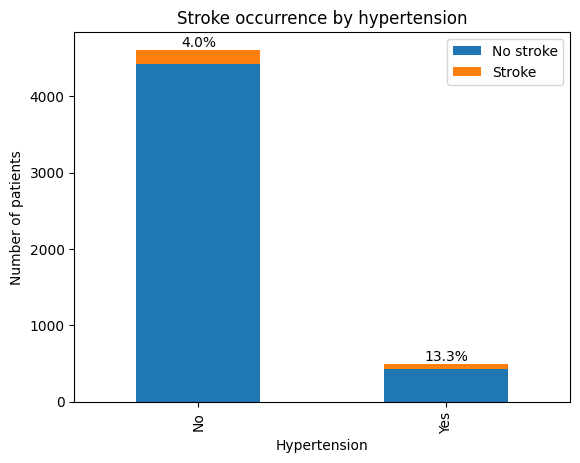

In [51]:
cross = pd.crosstab(data["Hypertension"], data["Stroke"])

make_barplot(cross)

plt.xlabel("Hypertension")
plt.ylabel("Number of patients")
plt.title("Stroke occurrence by hypertension")
plt.legend(["No stroke", "Stroke"])
plt.show()

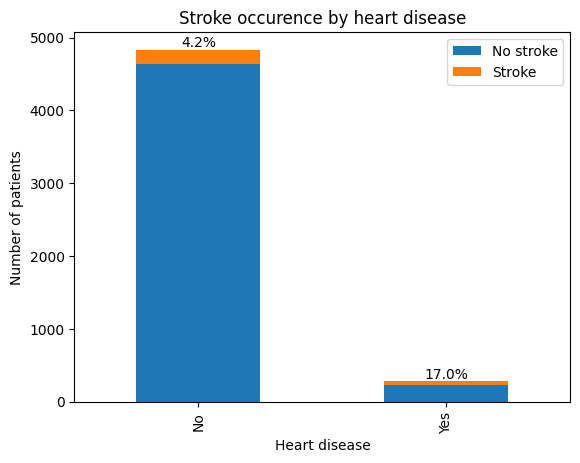

In [52]:
cross = pd.crosstab(data["Heart_disease"], data["Stroke"])

make_barplot(cross)

plt.title("Stroke occurence by heart disease")
plt.xlabel("Heart disease")
plt.ylabel("Number of patients")
plt.legend(["No stroke", "Stroke"])
plt.show()

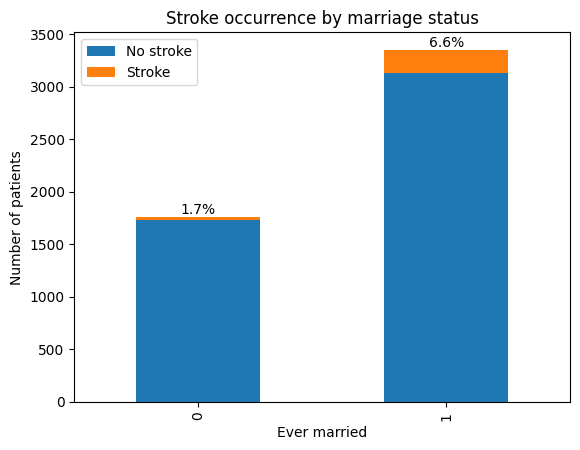

In [53]:
cross = pd.crosstab(data["Ever_married"], data["Stroke"])

make_barplot(cross)

plt.title("Stroke occurrence by marriage status")
plt.xlabel("Ever married")
plt.ylabel("Number of patients")
plt.legend(["No stroke", "Stroke"])
plt.show()

KeyError: 'Yes'

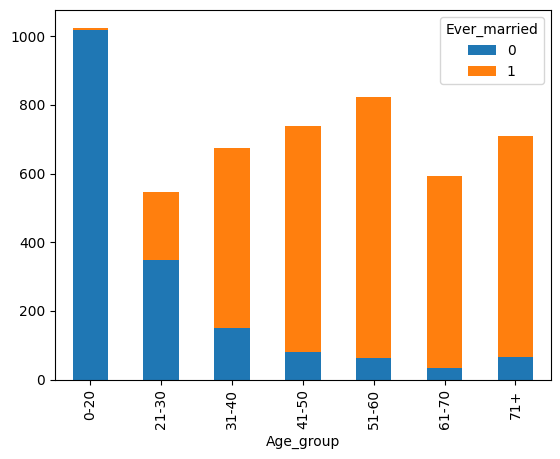

In [54]:
bins = [0, 20, 30, 40, 50, 60, 70, 100]  
labels = ["0-20", "21-30", "31-40", "41-50", "51-60", "61-70", "71+"]

data["Age_group"] = pd.cut(data["Age"], bins=bins, labels=labels)

cross = pd.crosstab(data["Age_group"], data["Ever_married"])

make_barplot(cross)

plt.title("Age and marriage dependency")
plt.xlabel("Age")
plt.ylabel("Number of people")
plt.legend(["Not married", "Married"])
plt.show()



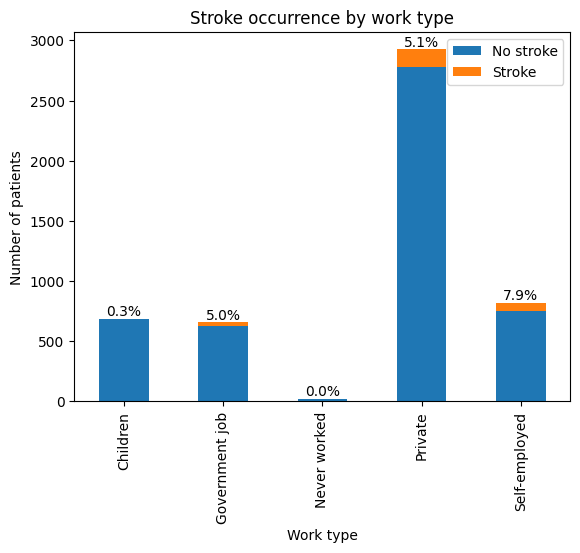

In [ ]:
cross = pd.crosstab(data["Work_type"], data["Stroke"])

make_barplot(cross)

plt.title("Stroke occurrence by work type")
plt.ylabel("Number of patients")
plt.xlabel("Work type")
plt.legend(["No stroke", "Stroke"])
plt.show()

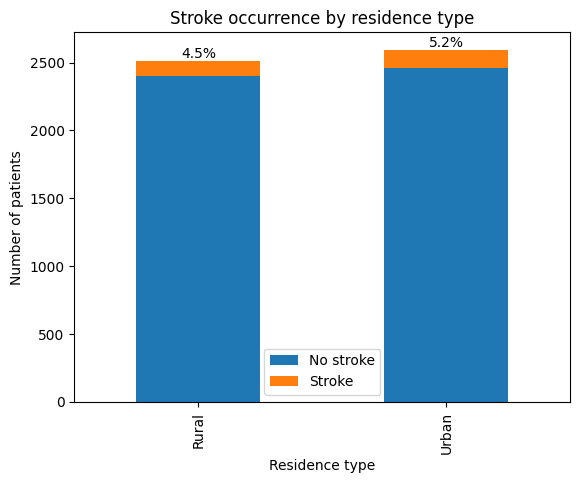

In [ ]:
cross = pd.crosstab(data["Residence_type"], data["Stroke"])

make_barplot(cross)

plt.title("Stroke occurrence by residence type")
plt.ylabel("Number of patients")
plt.xlabel("Residence type")
plt.legend(["No stroke", "Stroke"])
plt.show()

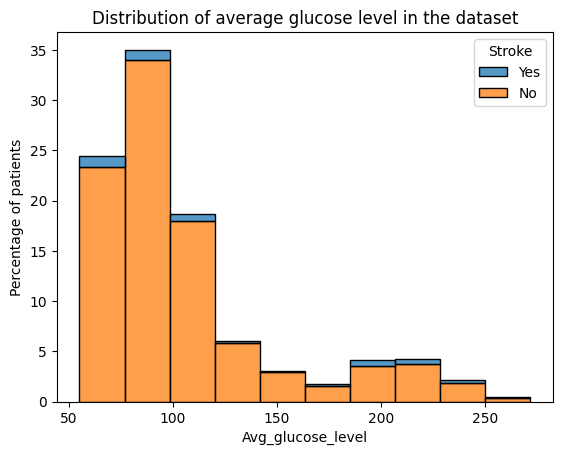

In [ ]:
sns.histplot(data=data, x="Avg_glucose_level", bins=10, hue="Stroke", multiple="stack", stat="percent")
plt.title("Distribution of average glucose level in the dataset")
plt.ylabel("Percentage of patients")
plt.show()

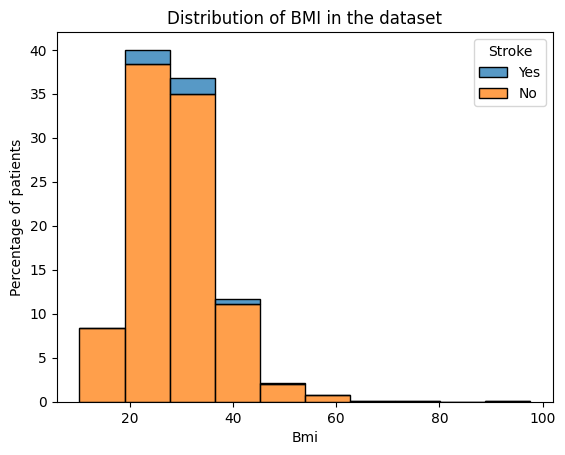

In [ ]:
sns.histplot(data=data, x="Bmi", bins=10, hue="Stroke", multiple="stack", stat="percent")
plt.title("Distribution of BMI in the dataset")
plt.ylabel("Percentage of patients")
plt.show()


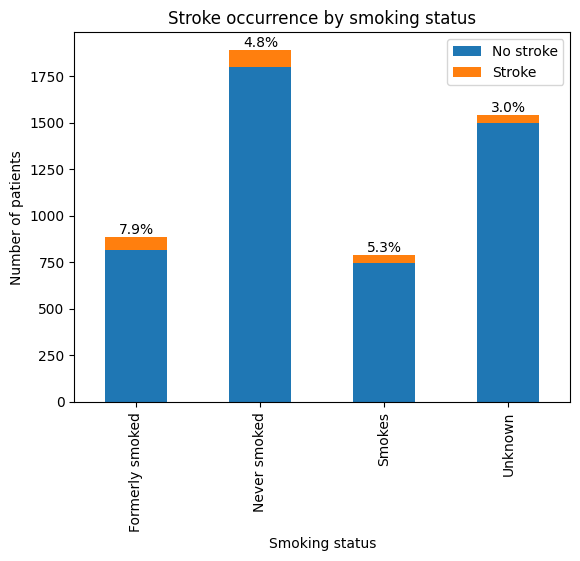

In [ ]:
cross = pd.crosstab(data["Smoking_status"], data["Stroke"])

make_barplot(cross)

plt.title("Stroke occurrence by smoking status")
plt.ylabel("Number of patients")
plt.xlabel("Smoking status")
plt.legend(["No stroke", "Stroke"])
plt.show()

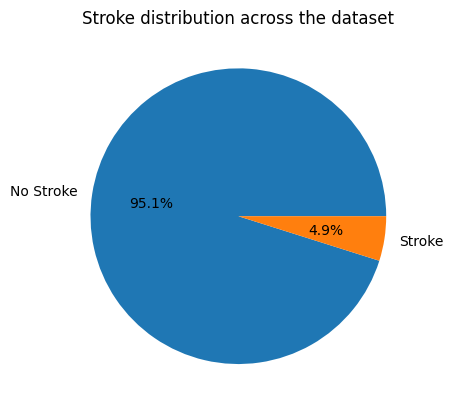

In [ ]:
stroke_counts = data["Stroke"].value_counts()
labels = ["No Stroke", "Stroke"]

plt.pie(
    stroke_counts,
    labels=labels,
    autopct="%1.1f%%"    
)
plt.title("Stroke distribution across the dataset")
plt.show()